In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import seaborn as sns
import warnings

# Import dữ liệu

In [14]:
df_sales = pd.read_csv('dataset/sales.csv')
df_inventory = pd.read_csv('dataset/inventory.csv')
df_customer = pd.read_csv('dataset/customers.csv')
df_order_items = pd.read_csv('dataset/order_items.csv')
df_web_traffic = pd.read_csv('dataset/web_traffic.csv')
df_returns = pd.read_csv('dataset/returns.csv')
df_payments = pd.read_csv('dataset/payments.csv')
df_orders = pd.read_csv('dataset/orders.csv')
df_products = pd.read_csv('dataset/products.csv')
df_geography = pd.read_csv('dataset/geography.csv')
df_promotion = pd.read_csv('dataset/promotions.csv')

C:\Users\MAN NHI\AppData\Local\Temp\ipykernel_5488\2293638694.py:4: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  df_order_items = pd.read_csv('dataset/order_items.csv')


In [15]:
df_sales['Date'] = pd.to_datetime(df_sales['Date'])
print(df_sales)

           Date     Revenue        COGS
0    2012-07-04  5123547.94  3982991.19
1    2012-07-05  2751773.45  2150580.23
2    2012-07-06  3054029.42  2517632.84
3    2012-07-07  2667930.94  2108246.62
4    2012-07-08  2360851.90  1808622.79
...         ...         ...         ...
3828 2022-12-27  2100553.66  2184872.24
3829 2022-12-28  3448729.20  3513621.00
3830 2022-12-29  3083944.33  3170787.10
3831 2022-12-30  2884668.76  3022292.15
3832 2022-12-31  2383037.48  2279288.13

[3833 rows x 3 columns]


In [16]:
PALETTE = ['#f74f6b', '#4f8ef7', '#f7c948', '#4fcfa8', '#a78bfa', '#fb923c']

## 1. Promotion có thật sự hiệu quả không?

In [17]:
df_orders = pd.read_csv('dataset/orders.csv', parse_dates=['order_date'])
df_order_items = pd.read_csv('dataset/order_items.csv', dtype={'promo_id': 'string','promo_id_2': 'string'})
df_promotions =  pd.read_csv('dataset/promotions.csv', parse_dates=['start_date', 'end_date'])

In [18]:
df_base = df_order_items.merge(
    df_orders[['order_id', 'order_date']],
    on='order_id',
    how='left'
)

df_base['gross_revenue'] = df_base['quantity'] * df_base['unit_price']
df_base['net_revenue'] = df_base['gross_revenue'] - df_base['discount_amount']

In [19]:
df_order_items_1 = df_order_items[['order_id', 'product_id', 'promo_id']].rename(columns={'promo_id': 'promo'})
df_order_items_2 = df_order_items[['order_id', 'product_id', 'promo_id_2']].rename(columns={'promo_id_2': 'promo'})

df_promo_long = pd.concat([df_order_items_1, df_order_items_2], ignore_index=True)

df_promo_long = df_promo_long.dropna(subset=['promo'])

df_promo_long = df_promo_long.merge(
    df_promotions[['promo_id','promo_type','stackable_flag','start_date','end_date']],
    left_on='promo',
    right_on='promo_id',
    how='left')

df_final = df_base.merge(
    df_promo_long.drop_duplicates(['order_id','product_id','promo']),
    on=['order_id','product_id'],
    how='left')

In [20]:
promo_info = df_promo_long.groupby('promo').agg({
    'promo_type': 'first',
    'stackable_flag': 'first',
    'start_date': 'first',
    'end_date': 'first'}).reset_index()

results = []

for _, promo in promo_info.iterrows():
    start = promo['start_date']
    end = promo['end_date']

    before = df_base[
        (df_base['order_date'] >= start - pd.Timedelta(days=7)) &
        (df_base['order_date'] < start)
    ]['net_revenue'].sum()

    during = df_base[
        (df_base['order_date'] >= start) &
        (df_base['order_date'] <= end)
    ]['net_revenue'].sum()

    after = df_base[
        (df_base['order_date'] > end) &
        (df_base['order_date'] <= end + pd.Timedelta(days=7))
    ]['net_revenue'].sum()

    results.append({
        'promo': promo['promo'],
        'promo_type': promo['promo_type'],
        'stackable_flag': promo['stackable_flag'],
        'before': before,
        'during': during,
        'after': after,
        'lift': during - before,
        'post_drop': after - before
    })

promo_eval = pd.DataFrame(results)

In [21]:
summary = promo_eval.groupby(
    ['promo_type', 'stackable_flag']
).agg({
    'lift': 'mean',
    'post_drop': 'mean'
}).reset_index()

print(summary)

   promo_type  stackable_flag          lift     post_drop
0       fixed               0  8.555580e+07 -1.881512e+07
1  percentage               0  8.620149e+07 -7.673113e+06
2  percentage               1  1.068991e+08  2.359360e+06


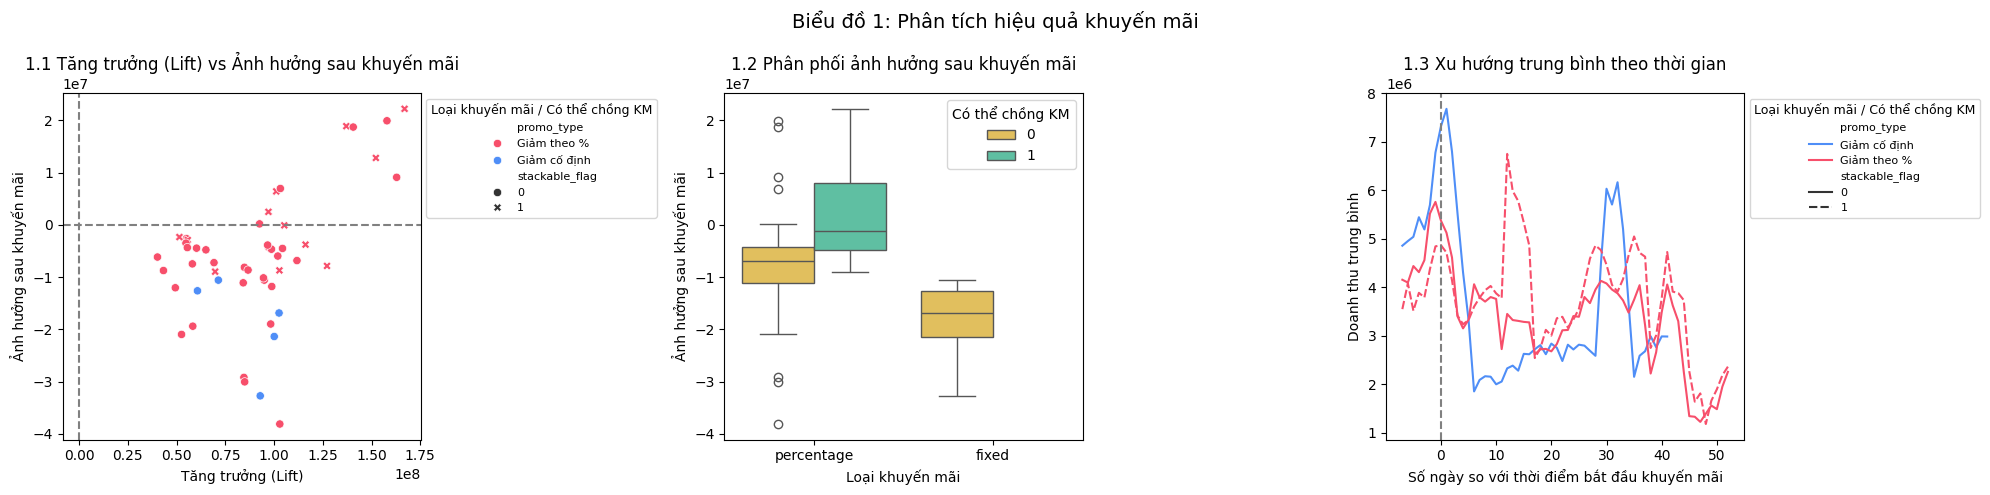

In [22]:
palette_main = {
    'percentage': PALETTE[0],
    'fixed': PALETTE[1]
}

fig, axes = plt.subplots(1, 3, figsize=(20,5))

# 1. Scatter: Lift vs Post
sns.scatterplot(
    data=promo_eval,
    x='lift',
    y='post_drop',
    hue='promo_type',
    style='stackable_flag',
    palette=palette_main,
    ax=axes[0]
)

axes[0].axhline(0, linestyle='--', color='gray')
axes[0].axvline(0, linestyle='--', color='gray')
axes[0].set_title('1.1 Tăng trưởng (Lift) vs Ảnh hưởng sau khuyến mãi')
axes[0].legend(
    title='Loại khuyến mãi / Có thể chồng KM',
    fontsize=8,
    title_fontsize=9,
    loc='upper left',
    bbox_to_anchor=(1, 1))
for text in axes[0].legend_.texts:
    if text.get_text() == 'percentage':
        text.set_text('Giảm theo %')
    elif text.get_text() == 'fixed':
        text.set_text('Giảm cố định')
    elif text.get_text() == 'True':
        text.set_text('Có thể áp dụng chồng')
    elif text.get_text() == 'False':
        text.set_text('Không áp dụng chồng')
axes[0].set_xlabel('Tăng trưởng (Lift)')
axes[0].set_ylabel('Ảnh hưởng sau khuyến mãi')

# 2. Boxplot: Post-effect distribution
sns.boxplot(
    data=promo_eval,
    x='promo_type',
    y='post_drop',
    hue='stackable_flag',
    palette=[PALETTE[2], PALETTE[3]],
    ax=axes[1]
)

axes[1].set_title('1.2 Phân phối ảnh hưởng sau khuyến mãi')
axes[1].legend(title='Có thể chồng KM')
for text in axes[1].legend_.texts:
    if text.get_text() == 'True':
        text.set_text('Có thể áp dụng chồng')
    elif text.get_text() == 'False':
        text.set_text('Không áp dụng chồng')
axes[1].set_xlabel('Loại khuyến mãi')
axes[1].set_ylabel('Ảnh hưởng sau khuyến mãi')

# 3. Average Time-series
all_curves = []

for _, promo in promo_info.iterrows():
    start = promo['start_date']
    end = promo['end_date']

    window_start = start - pd.Timedelta(days=7)
    window_end = end + pd.Timedelta(days=7)

    df_plot = df_base[
        (df_base['order_date'] >= window_start) &
        (df_base['order_date'] <= window_end)
    ].copy()

    df_daily = df_plot.groupby('order_date')['net_revenue'].sum()

    all_dates = pd.date_range(window_start, window_end)

    df_daily = df_daily.reindex(all_dates, fill_value=0)

    df_daily = df_daily.reset_index()
    df_daily.columns = ['date', 'revenue']

    df_daily['day'] = (df_daily['date'] - start).dt.days
    df_daily['promo_type'] = promo['promo_type']
    df_daily['stackable_flag'] = promo['stackable_flag']

    all_curves.append(df_daily)

df_all = pd.concat(all_curves)

df_avg = df_all.groupby(
    ['day','promo_type','stackable_flag']
)['revenue'].mean().reset_index()

sns.lineplot(
    data=df_avg,
    x='day',
    y='revenue',
    hue='promo_type',
    style='stackable_flag',
    palette=palette_main,
    ax=axes[2]
)

axes[2].axvline(0, linestyle='--', color='gray')
axes[2].set_title('1.3 Xu hướng trung bình theo thời gian')
axes[2].legend(
    title='Loại khuyến mãi / Có thể chồng KM',
    fontsize=8,
    title_fontsize=9,
    loc='upper left',
    bbox_to_anchor=(1, 1))
for text in axes[2].legend_.texts:
    if text.get_text() == 'percentage':
        text.set_text('Giảm theo %')
    elif text.get_text() == 'fixed':
        text.set_text('Giảm cố định')
    elif text.get_text() == 'True':
        text.set_text('Có thể áp dụng chồng')
    elif text.get_text() == 'False':
        text.set_text('Không áp dụng chồng')
axes[2].set_xlabel('Số ngày so với thời điểm bắt đầu khuyến mãi')
axes[2].set_ylabel('Doanh thu trung bình')

plt.suptitle('Biểu đồ 1: Phân tích hiệu quả khuyến mãi', fontsize=14)
plt.tight_layout()
plt.show()

In [23]:
def get_promo_timeseries(promo_id):
    promo = promo_info[promo_info['promo'] == promo_id].iloc[0]

    start = promo['start_date']
    end = promo['end_date']

    window_start = start - pd.Timedelta(days=7)
    window_end = end + pd.Timedelta(days=7)

    df_plot = df_base[
        (df_base['order_date'] >= window_start) &
        (df_base['order_date'] <= window_end)
    ].copy()

    # Aggregate theo ngày
    df_plot_daily = df_plot.groupby('order_date')['net_revenue'].sum().reset_index()

    # Fill missing dates
    all_dates = pd.date_range(window_start, window_end)

    df_plot_daily = (
        df_plot_daily
        .set_index('order_date')
        .reindex(all_dates, fill_value=0)
        .reset_index()
    )

    df_plot_daily.columns = ['date', 'revenue']

    # Tạo relative day
    df_plot_daily['day'] = (df_plot_daily['date'] - start).dt.days

    return df_plot_daily, start, end

In [24]:
# 1. percentage - stack
df_stack = promo_eval[
    (promo_eval['promo_type'] == 'percentage') &
    (promo_eval['stackable_flag'] == 1) &
    (promo_eval['post_drop'] >= 0)
]

promo_stack = df_stack.sort_values('lift').iloc[len(df_stack)//2]['promo']


# 2. percentage - non-stack
df_pct = promo_eval[
    (promo_eval['promo_type'] == 'percentage') &
    (promo_eval['stackable_flag'] == 0)
]

promo_pct = df_pct.sort_values('lift').iloc[len(df_pct)//2]['promo']


# 3. fixed - non-stack
df_fixed = promo_eval[
    (promo_eval['promo_type'] == 'fixed')
]

promo_fixed = df_fixed.sort_values('lift').iloc[len(df_fixed)//2]['promo']

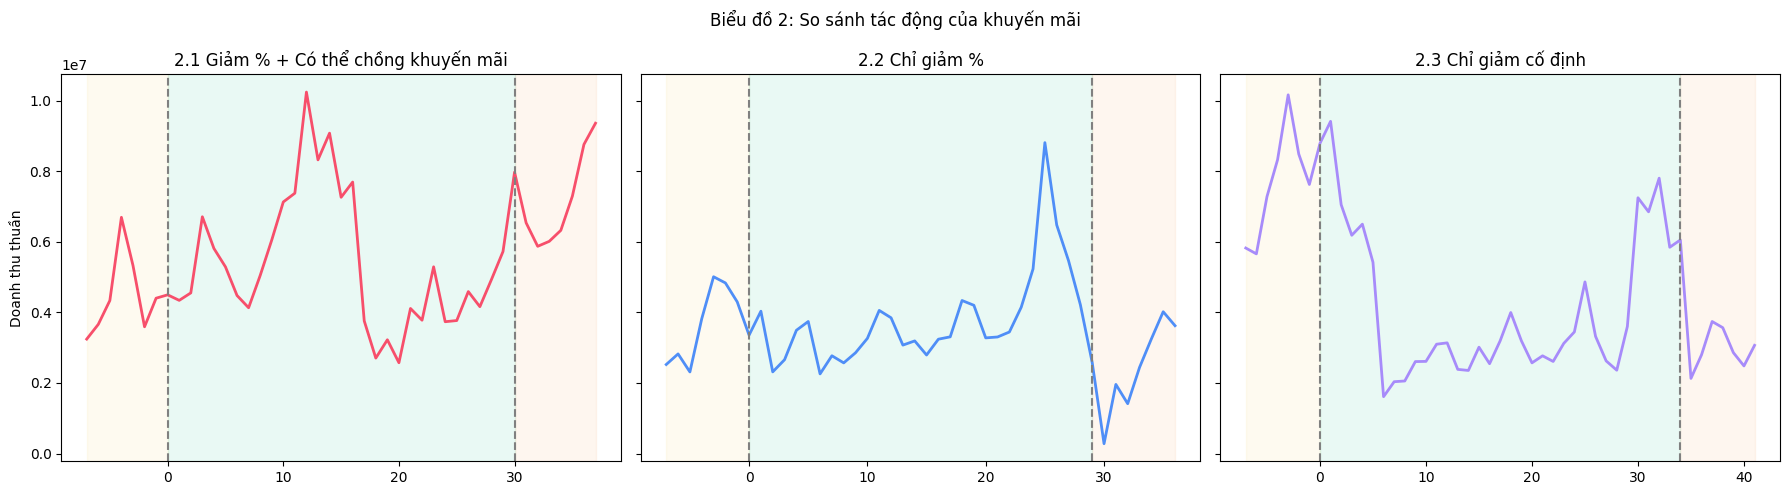

In [25]:
colors = [PALETTE[0], PALETTE[1], PALETTE[4]]

fig, axes = plt.subplots(1, 3, figsize=(18,5), sharey=True)

promo_list = [
    (promo_stack, '2.1 Giảm % + Có thể chồng khuyến mãi'),
    (promo_pct, '2.2 Chỉ giảm %'),
    (promo_fixed, '2.3 Chỉ giảm cố định')
]

for ax, (promo_id, title), color in zip(axes, promo_list, colors):
    
    df_plot_daily, start, end = get_promo_timeseries(promo_id)

    ax.plot(df_plot_daily['day'], df_plot_daily['revenue'], color=color, linewidth=2)

    # Highlight vùng
    ax.axvspan(-7, 0, alpha=0.08, color=PALETTE[2])
    ax.axvspan(0, (end - start).days, alpha=0.12, color=PALETTE[3])
    ax.axvspan((end - start).days, (end - start).days + 7, alpha=0.08, color=PALETTE[5])

    ax.axvline(0, linestyle='--', color='gray')
    ax.axvline((end - start).days, linestyle='--', color='gray')

    ax.set_title(title)

axes[0].set_ylabel('Doanh thu thuần')

plt.suptitle('Biểu đồ 2: So sánh tác động của khuyến mãi')
plt.tight_layout()
plt.show()

## 2. Hiệu quả doanh thu dựa trên chất lượng truy cập WEB

In [26]:
df_orders.columns = df_orders.columns.str.strip().str.lower()
df_payments.columns = df_payments.columns.str.strip().str.lower()
df_web_traffic.columns = df_web_traffic.columns.str.strip().str.lower()

# Convert date
df_orders["order_date"] = pd.to_datetime(df_orders["order_date"])
df_web_traffic["date"] = pd.to_datetime(df_web_traffic["date"])

# Clean source text
df_orders["order_source"] = df_orders["order_source"].astype(str).str.strip().str.lower()
df_web_traffic["traffic_source"] = df_web_traffic["traffic_source"].astype(str).str.strip().str.lower()

print("Order source:")
print(df_orders["order_source"].value_counts())

print("\nTraffic source:")
print(df_web_traffic["traffic_source"].value_counts())

Order source:
order_source
organic_search    181495
paid_search       141652
social_media      129710
email_campaign     77572
referral           64565
direct             51951
Name: count, dtype: int64

Traffic source:
traffic_source
organic_search    1090
paid_search        784
social_media       632
email_campaign     505
referral           375
direct             266
Name: count, dtype: int64


In [27]:
# REVENUE FROM ORDERS + PAYMENTS
order_payment = df_orders.merge(
    df_payments[["order_id", "payment_value"]],
    on="order_id",
    how="left"
)

daily_source_revenue = (
    order_payment
    .groupby(["order_date", "order_source"], as_index=False)
    .agg(
        revenue=("payment_value", "sum"),
        orders=("order_id", "nunique")
    )
    .rename(columns={
        "order_date": "date",
        "order_source": "source"
    })
)

daily_source_traffic = (
    df_web_traffic
    .groupby(["date", "traffic_source"], as_index=False)
    .agg(
        sessions=("sessions", "sum"),
        unique_visitors=("unique_visitors", "sum"),
        page_views=("page_views", "sum"),
        bounce_rate=("bounce_rate", "mean"),
        avg_session_duration_sec=("avg_session_duration_sec", "mean")
    )
    .rename(columns={
        "traffic_source": "source"
    })
)

source_daily_perf = daily_source_traffic.merge(
    daily_source_revenue,
    on=["date", "source"],
    how="inner"
)

source_daily_perf.head()

,date,source,sessions,unique_visitors,page_views,bounce_rate,avg_session_duration_sec,revenue,orders
0,2013-01-01,organic_search,9760,7253,39093,0.00514,102.9,1501578.07,80
1,2013-01-02,organic_search,10456,8151,47611,0.00406,120.5,766660.48,18
2,2013-01-03,direct,10076,7458,36963,0.00401,263.6,167151.91,4
3,2013-01-04,direct,9973,8063,53078,0.00562,151.8,130838.23,5
4,2013-01-05,referral,10223,7882,36790,0.00525,168.6,258038.00,8


In [28]:
# SOURCE PERFORMANCE SUMMARY
source_perf = (
    source_daily_perf
    .groupby("source", as_index=False)
    .agg(
        sessions=("sessions", "sum"),
        revenue=("revenue", "sum"),
        orders=("orders", "sum"),
        unique_visitors=("unique_visitors", "sum"),
        page_views=("page_views", "sum"),
        bounce_rate=("bounce_rate", "mean"),
        avg_session_duration_sec=("avg_session_duration_sec", "mean")
    )
)

source_perf["revenue_per_session"] = source_perf["revenue"] / source_perf["sessions"]
source_perf["orders_per_session"] = source_perf["orders"] / source_perf["sessions"]
source_perf["conversion_rate_%"] = source_perf["orders_per_session"] * 100
source_perf["page_views_per_session"] = source_perf["page_views"] / source_perf["sessions"]

source_perf = source_perf.sort_values("revenue_per_session", ascending=False)

source_perf

,source,sessions,revenue,orders,unique_visitors,page_views,bounce_rate,avg_session_duration_sec,revenue_per_session,orders_per_session,conversion_rate_%,page_views_per_session
2,organic_search,27196976,1.214210e+09,50534,20625107,117606452,0.004504,211.153945,44.645046,0.001858,0.185807,4.324247
3,paid_search,19598271,7.144334e+08,29203,14922386,85079551,0.004478,209.362117,36.453899,0.001490,0.149008,4.341176
5,social_media,15800382,5.332840e+08,21999,12035946,67985334,0.004476,210.377813,33.751333,0.001392,0.139231,4.302765
1,email_campaign,12772146,2.490862e+08,10135,9684548,55377307,0.004458,213.119841,19.502301,0.000794,0.079352,4.335787
4,referral,9476845,1.528173e+08,6197,7220019,41655659,0.004499,207.558667,16.125337,0.000654,0.065391,4.395520
0,direct,6556269,8.380575e+07,3518,4974930,28709433,0.004511,207.429057,12.782537,0.000537,0.053659,4.378928


In [29]:
# Revenue theo ngày từ sales.csv
daily_revenue = (
    df_sales
    .groupby("Date", as_index=False)["Revenue"]
    .sum()
    .rename(columns={
        "Date": "date",
        "Revenue": "revenue"
    })
)

# Traffic theo ngày
daily_traffic = (
    df_web_traffic
    .groupby("date", as_index=False)
    .agg({
        "sessions": "sum",
        "unique_visitors": "sum",
        "page_views": "sum",
        "bounce_rate": "mean",
        "avg_session_duration_sec": "mean"
    })
)

# Gộp lại thành daily_perf
daily_perf = daily_traffic.merge(daily_revenue, on="date", how="inner")
daily_perf = daily_perf.sort_values("date")

# Thêm chỉ số revenue per session
daily_perf["revenue_per_session"] = daily_perf["revenue"] / daily_perf["sessions"]

daily_perf.head()

,date,sessions,unique_visitors,page_views,bounce_rate,avg_session_duration_sec,revenue,revenue_per_session
0,2013-01-01,9760,7253,39093,0.00514,102.9,5304546.99,543.498667
1,2013-01-02,10456,8151,47611,0.00406,120.5,1606940.44,153.685964
2,2013-01-03,10076,7458,36963,0.00401,263.6,2281680.01,226.447004
3,2013-01-04,9973,8063,53078,0.00562,151.8,2376895.46,238.333045
4,2013-01-05,10223,7882,36790,0.00525,168.6,2509462.77,245.472246


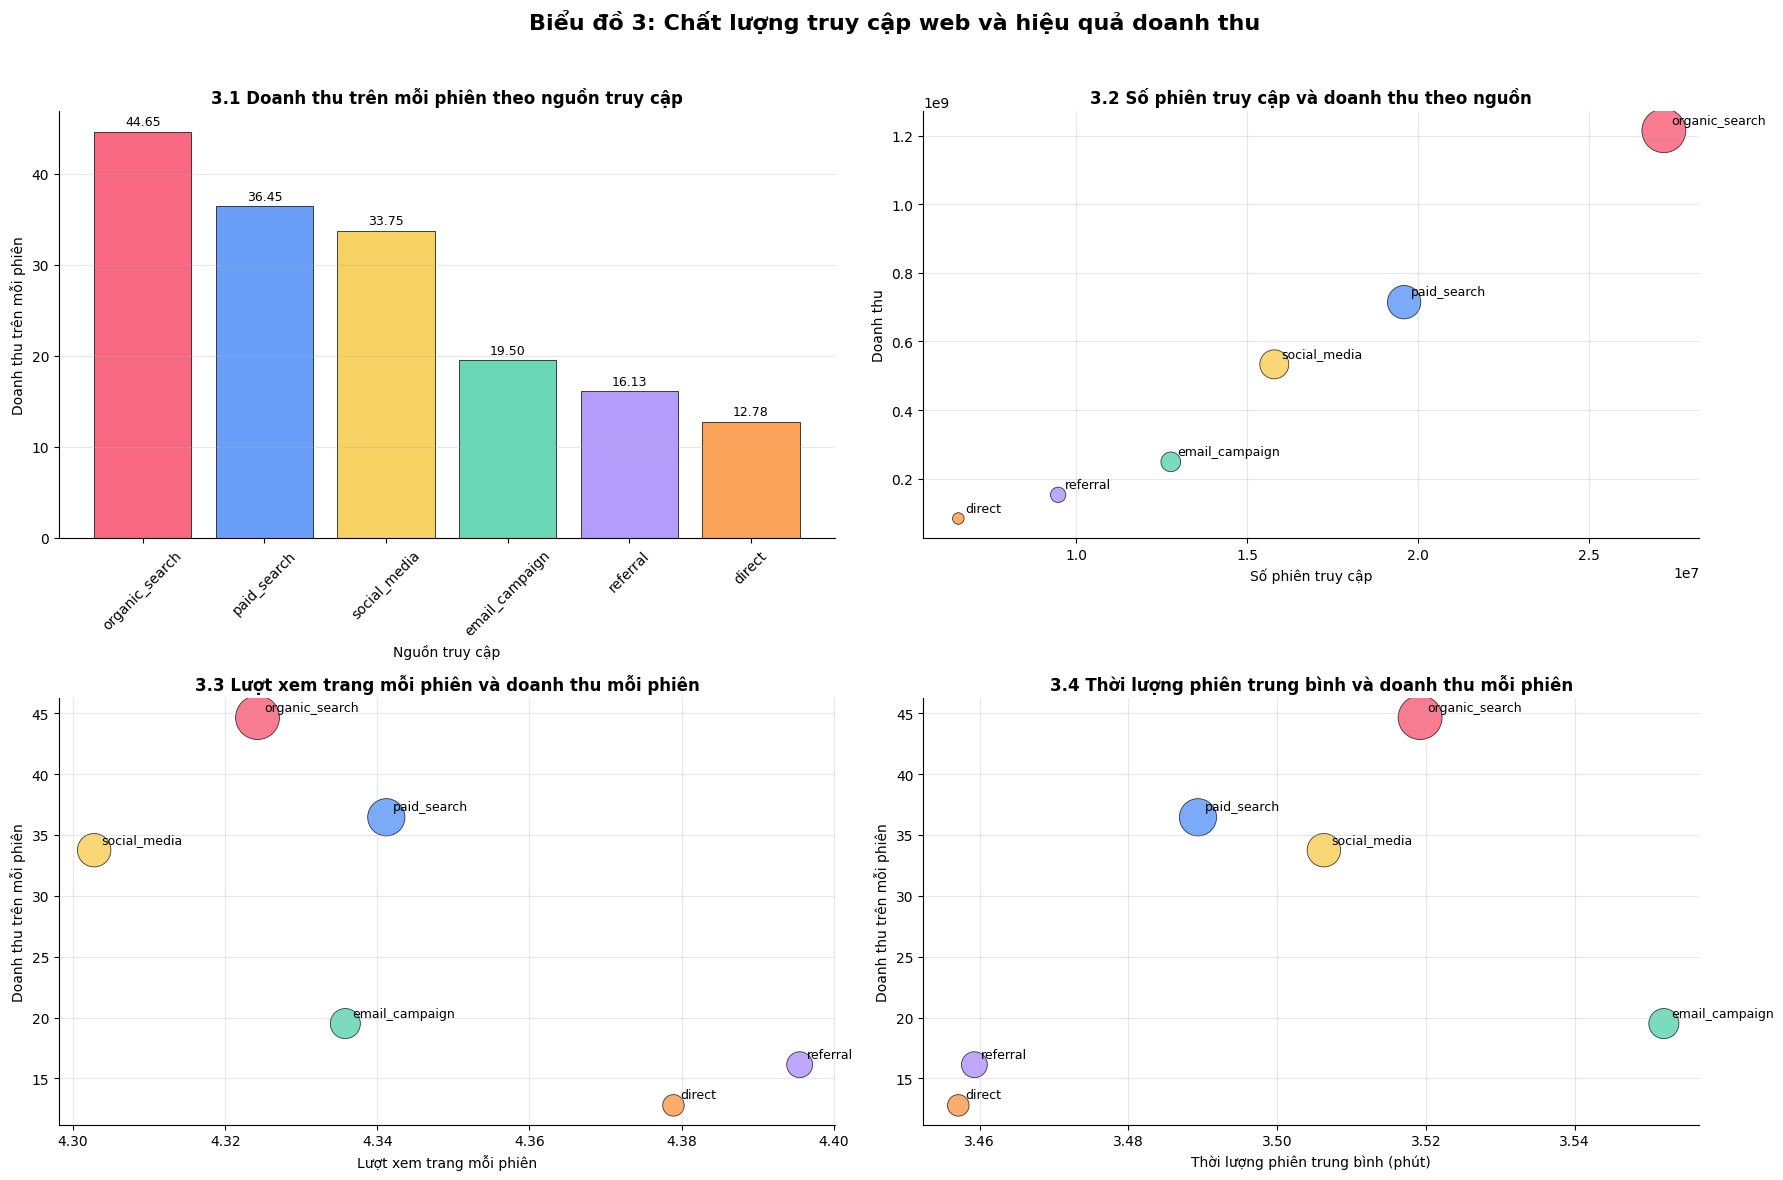

In [30]:
sp = source_perf.copy()
sp = sp.sort_values("revenue_per_session", ascending=False).reset_index(drop=True)

# Tạo các chỉ số thể hiện mức độ tương tác
sp["page_views_per_session"] = sp["page_views"] / sp["sessions"]
sp["avg_session_duration_min"] = sp["avg_session_duration_sec"] / 60

# Kích thước bubble
bubble_orders = np.where(
    sp["orders"] > 0,
    sp["orders"] / sp["orders"].max() * 1000,
    200
)

bubble_sessions = np.where(
    sp["sessions"] > 0,
    sp["sessions"] / sp["sessions"].max() * 1000,
    200
)

PALETTE = ["#f74f6b", "#4f8ef7", "#f7c948", "#4fcfa8", "#a78bfa", "#fb923c"]

sources = list(sp["source"].unique())
source_colors = dict(zip(sources, PALETTE[:len(sources)]))

bar_colors = [source_colors[src] for src in sp["source"]]
scatter_colors = [source_colors[src] for src in sp["source"]]

# Format biểu đồ
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

fig.suptitle(
    "Biểu đồ 3: Chất lượng truy cập web và hiệu quả doanh thu",
    fontsize=16,
    fontweight="bold"
)

# Biểu đồ 1
bars = axes[0, 0].bar(
    sp["source"],
    sp["revenue_per_session"],
    color=bar_colors,
    alpha=0.85,
    edgecolor="black",
    linewidth=0.6
)

axes[0, 0].set_title("3.1 Doanh thu trên mỗi phiên theo nguồn truy cập", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Nguồn truy cập")
axes[0, 0].set_ylabel("Doanh thu trên mỗi phiên")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].grid(True, axis="y", alpha=0.3)

for bar in bars:
    height = bar.get_height()
    axes[0, 0].text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.4,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Biểu đồ 2
axes[0, 1].scatter(
    sp["sessions"],
    sp["revenue"],
    s=bubble_orders,
    c=scatter_colors,
    alpha=0.75,
    edgecolor="black",
    linewidth=0.6
)

for _, row in sp.iterrows():
    axes[0, 1].annotate(
        row["source"],
        (row["sessions"], row["revenue"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

axes[0, 1].set_title("3.2 Số phiên truy cập và doanh thu theo nguồn", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Số phiên truy cập")
axes[0, 1].set_ylabel("Doanh thu")
axes[0, 1].grid(True, alpha=0.3)

# Biểu đồ 3
axes[1, 0].scatter(
    sp["page_views_per_session"],
    sp["revenue_per_session"],
    s=bubble_sessions,
    c=scatter_colors,
    alpha=0.75,
    edgecolor="black",
    linewidth=0.6
)

for _, row in sp.iterrows():
    axes[1, 0].annotate(
        row["source"],
        (row["page_views_per_session"], row["revenue_per_session"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

axes[1, 0].set_title("3.3 Lượt xem trang mỗi phiên và doanh thu mỗi phiên", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Lượt xem trang mỗi phiên")
axes[1, 0].set_ylabel("Doanh thu trên mỗi phiên")
axes[1, 0].grid(True, alpha=0.3)

# Biểu đồ 4
axes[1, 1].scatter(
    sp["avg_session_duration_min"],
    sp["revenue_per_session"],
    s=bubble_sessions,
    c=scatter_colors,
    alpha=0.75,
    edgecolor="black",
    linewidth=0.6
)

for _, row in sp.iterrows():
    axes[1, 1].annotate(
        row["source"],
        (row["avg_session_duration_min"], row["revenue_per_session"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

axes[1, 1].set_title("3.4 Thời lượng phiên trung bình và doanh thu mỗi phiên", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Thời lượng phiên trung bình (phút)")
axes[1, 1].set_ylabel("Doanh thu trên mỗi phiên")
axes[1, 1].grid(True, alpha=0.3)

for ax in axes.flatten():
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 3. Customer

In [31]:
df_customers = pd.read_csv('dataset/customers.csv', parse_dates=['signup_date'])

In [32]:
df_final_1 = df_order_items.merge(df_orders[['order_id', 'order_date', 'customer_id']], on='order_id', how='left')

df_final_1['gross'] = df_final_1['quantity'] * df_final_1['unit_price']
df_final_1['net_revenue'] = df_final_1['gross'] - df_final_1['discount_amount']

In [33]:
df_final_1 = df_final_1.merge(df_customers, on='customer_id', how='left')

In [34]:
# Cohort
df_final_1['signup_year'] = df_final_1['signup_date'].dt.year #năm đăng ký
df_final_1['order_year'] = df_final_1['order_date'].dt.year #năm mua hàng

In [35]:
# 1 Cohort heatmap
cohort_table = df_final_1.pivot_table(
    index='signup_year',
    columns='order_year',
    values='net_revenue',
    aggfunc='sum',
    fill_value=0
)

cohort_norm = cohort_table.div(cohort_table.iloc[:, 0], axis=0)
print(cohort_norm)

order_year   2012      2013      2014      2015      2016      2017      2018  \
signup_year                                                                     
2012          1.0  2.009621  2.576467  2.644898  2.540609  2.451679  2.131467   
2013          1.0  2.163794  2.583616  2.579873  3.041883  2.580035  2.441770   
2014          1.0  2.045436  2.267503  2.292830  2.614366  2.253718  2.382481   
2015          1.0  2.127518  2.459770  2.428063  2.798288  2.481662  2.501541   
2016          1.0  2.103833  2.397379  2.366635  2.675168  2.482931  2.313325   
2017          1.0  2.050920  2.272969  2.308256  2.519562  2.289203  2.292570   
2018          1.0  2.062661  2.301691  2.409851  2.672447  2.386305  2.359021   
2019          1.0  2.124798  2.431229  2.454026  2.720591  2.502213  2.355951   
2020          1.0  2.132872  2.405744  2.413521  2.711769  2.453671  2.353385   
2021          1.0  2.086329  2.428683  2.376579  2.664854  2.427144  2.347684   
2022          1.0  2.222991 

In [36]:
# 2 Revenue contribution
cohort_rev = df_final_1.groupby('signup_year')['net_revenue'].sum()
cohort_pct = cohort_rev / cohort_rev.sum()
old_cohort_rev = cohort_rev.loc[2012:2014].sum()
pct_old = old_cohort_rev / cohort_rev.sum()

print(f"Revenue từ cohort 2012–2014: {old_cohort_rev:,.0f}")
print(f"% đóng góp: {pct_old:.2%}")

Revenue từ cohort 2012–2014: 1,176,722,644
% đóng góp: 7.50%


In [37]:
# 3 LTV by channel
customer_ltv = df_final_1.groupby(['customer_id', 'acquisition_channel'])['net_revenue'].sum().reset_index()

ltv = customer_ltv.groupby('acquisition_channel').agg(
    avg_LTV=('net_revenue', 'mean'),
    median_LTV=('net_revenue', 'median'),
    num_customers=('net_revenue', 'count')).reset_index().sort_values(by='avg_LTV', ascending=False)

print(ltv)

  acquisition_channel        avg_LTV  median_LTV  num_customers
5        social_media  175458.143840   92181.970          18002
2      organic_search  174849.285008   90718.045          26950
3         paid_search  173475.155570   89668.910          17999
1      email_campaign  172414.694727   86667.530          10886
4            referral  171955.636015   89051.200           9072
0              direct  170480.619766   88171.440           7337


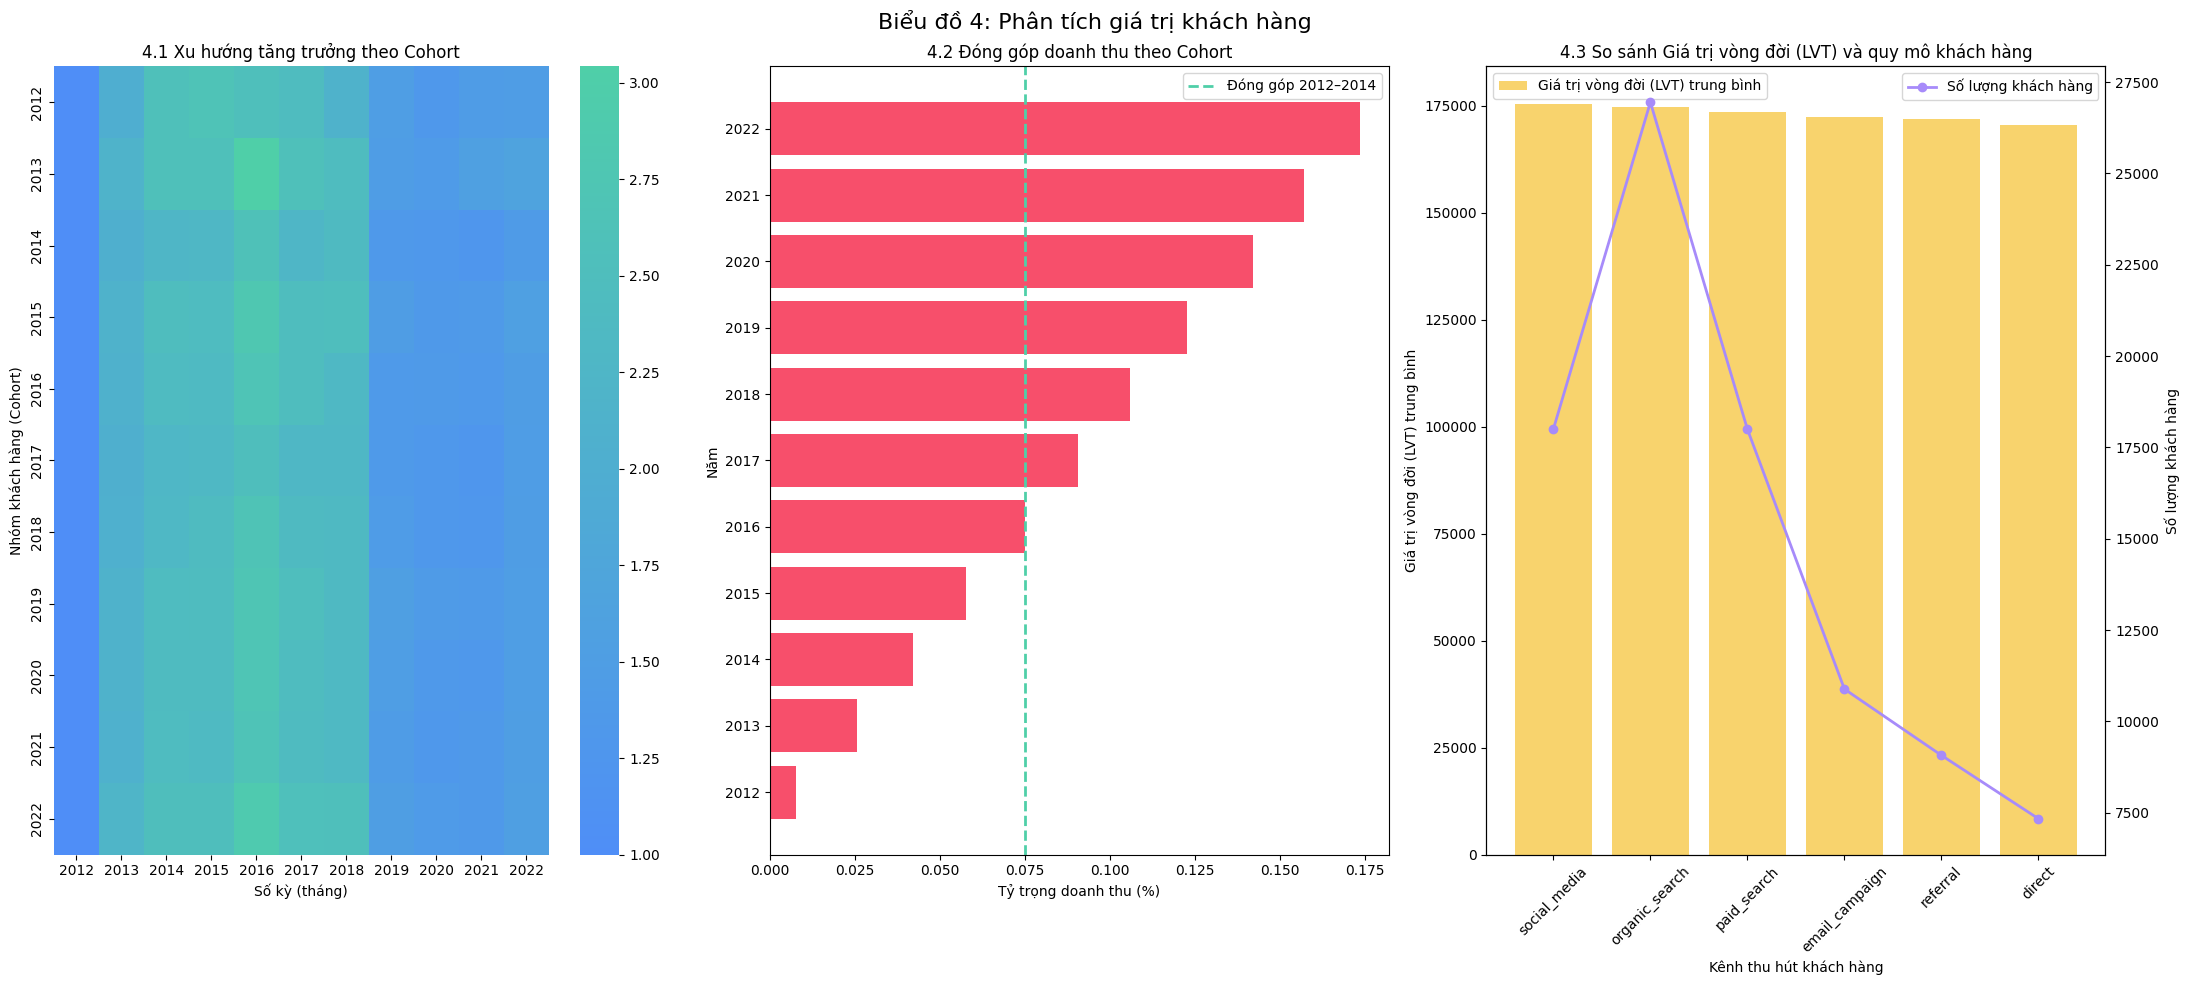

In [38]:
custom_cmap = LinearSegmentedColormap.from_list(
    "custom",
    [PALETTE[1], PALETTE[3]]
)

fig, axes = plt.subplots(1, 3, figsize=(22, 10))
fig.suptitle('Biểu đồ 4: Phân tích giá trị khách hàng', fontsize=16)

# Heatmap
sns.heatmap(cohort_norm, cmap=custom_cmap, ax=axes[0])
axes[0].set_title('4.1 Xu hướng tăng trưởng theo Cohort')
axes[0].set_xlabel('Số kỳ (tháng)')
axes[0].set_ylabel('Nhóm khách hàng (Cohort)')

# Contribution
axes[1].barh(cohort_pct.index.astype(str), cohort_pct.values, color=PALETTE[0])

val_early = cohort_pct.loc[2012:2014].sum()
axes[1].axvline(val_early,  color=PALETTE[3], linestyle='--', linewidth=2, label='Đóng góp 2012–2014')
axes[1].legend()
axes[1].set_title('4.2 Đóng góp doanh thu theo Cohort')
axes[1].set_xlabel('Tỷ trọng doanh thu (%)')
axes[1].set_ylabel('Năm')

# LTV
ax3 = axes[2]
ax3_twin = ax3.twinx()


ax3.bar(ltv['acquisition_channel'], ltv['avg_LTV'],  color=PALETTE[2], alpha=0.8, label='Giá trị vòng đời (LVT) trung bình')

ax3_twin.plot(ltv['acquisition_channel'], ltv['num_customers'], color=PALETTE[4], marker='o',linewidth=2, 
              label='Số lượng khách hàng', zorder=3)

ax3.set_title('4.3 So sánh Giá trị vòng đời (LVT) và quy mô khách hàng')
ax3.set_xlabel('Kênh thu hút khách hàng')
ax3.set_ylabel('Giá trị vòng đời (LVT) trung bình')
ax3_twin.set_ylabel('Số lượng khách hàng')
ax3.tick_params(axis='x', rotation=45)
ax3.legend(loc='upper left', bbox_to_anchor=(0, 1))
ax3_twin.legend(loc='upper right', bbox_to_anchor=(1, 1))
plt.tight_layout()

## 4. Rủi ro tồn kho

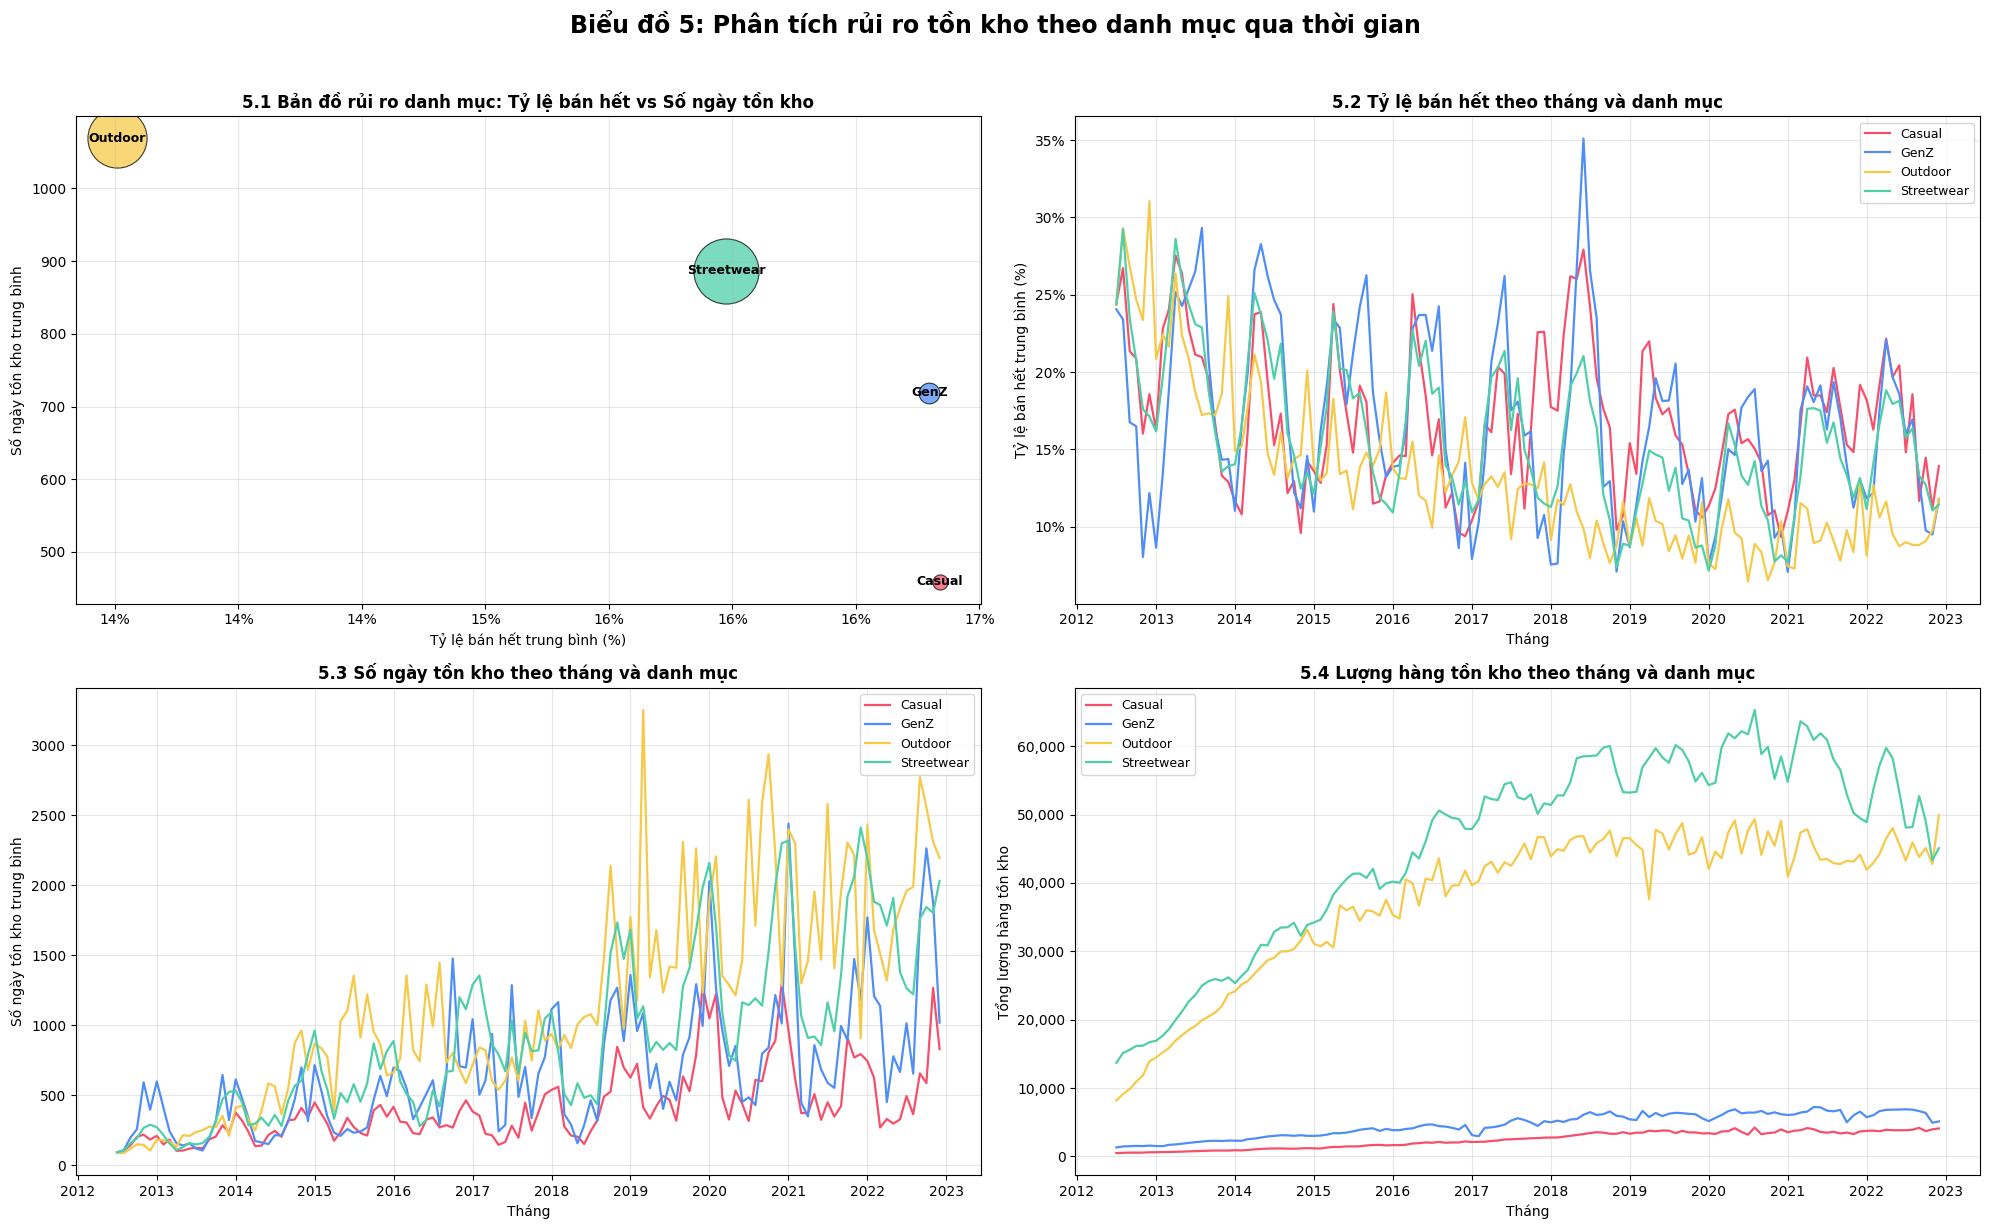

In [39]:
# Lấy tháng từ cột snapshot_date trong inventory.csv
df_inventory["snapshot_date"] = pd.to_datetime(df_inventory["snapshot_date"])
df_inventory["month_date"] = df_inventory["snapshot_date"].dt.to_period("M").dt.to_timestamp()

# Style
cats = sorted(df_inventory["category"].unique())
category_colors = dict(zip(cats, PALETTE[:len(cats)]))

# Tổng hợp toàn bộ 10 năm theo danh mục
category_summary = df_inventory.groupby("category").agg(
    avg_sell_through=("sell_through_rate", "mean"),
    avg_days_supply=("days_of_supply", "mean"),
    total_stock=("stock_on_hand", "sum")
).reset_index()

# Tổng hợp theo tháng và danh mục
monthly_summary = df_inventory.groupby(["month_date", "category"]).agg(
    avg_sell_through=("sell_through_rate", "mean"),
    avg_days_supply=("days_of_supply", "mean"),
    total_stock=("stock_on_hand", "sum")
).reset_index()

# Format
fig, axes = plt.subplots(2, 2, figsize=(20, 12))

fig.suptitle(
    "Biểu đồ 5: Phân tích rủi ro tồn kho theo danh mục qua thời gian",
    fontsize=17,
    fontweight="bold",
    y=1.02
)
# Biểu đồ 1
ax = axes[0, 0]

max_stock = category_summary["total_stock"].max()

for _, row in category_summary.iterrows():
    bubble_size = row["total_stock"] / max_stock * 2200
    
    ax.scatter(
        row["avg_sell_through"] * 100,
        row["avg_days_supply"],
        s=bubble_size,
        color=category_colors[row["category"]],
        alpha=0.75,
        edgecolor="black",
        linewidth=0.8
    )
    
    ax.text(
        row["avg_sell_through"] * 100,
        row["avg_days_supply"],
        row["category"],
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center"
    )

ax.set_title("5.1 Bản đồ rủi ro danh mục: Tỷ lệ bán hết vs Số ngày tồn kho", fontweight="bold")
ax.set_xlabel("Tỷ lệ bán hết trung bình (%)")
ax.set_ylabel("Số ngày tồn kho trung bình")
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))

# Biểu đồ 2
ax = axes[0, 1]

for cat in cats:
    data = monthly_summary[monthly_summary["category"] == cat]
    
    ax.plot(
        data["month_date"],
        data["avg_sell_through"] * 100,
        linewidth=1.6,
        label=cat,
        color=category_colors[cat]
    )

ax.set_title("5.2 Tỷ lệ bán hết theo tháng và danh mục", fontweight="bold")
ax.set_xlabel("Tháng")
ax.set_ylabel("Tỷ lệ bán hết trung bình (%)")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Biểu đồ 3
ax = axes[1, 0]

for cat in cats:
    data = monthly_summary[monthly_summary["category"] == cat]
    
    ax.plot(
        data["month_date"],
        data["avg_days_supply"],
        linewidth=1.6,
        label=cat,
        color=category_colors[cat]
    )

ax.set_title("5.3 Số ngày tồn kho theo tháng và danh mục", fontweight="bold")
ax.set_xlabel("Tháng")
ax.set_ylabel("Số ngày tồn kho trung bình")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Biểu đồ 4
ax = axes[1, 1]

for cat in cats:
    data = monthly_summary[monthly_summary["category"] == cat]
    
    ax.plot(
        data["month_date"],
        data["total_stock"],
        linewidth=1.6,
        label=cat,
        color=category_colors[cat]
    )

ax.set_title("5.4 Lượng hàng tồn kho theo tháng và danh mục", fontweight="bold")
ax.set_xlabel("Tháng")
ax.set_ylabel("Tổng lượng hàng tồn kho")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

plt.tight_layout()
plt.show()

## 5. Return

In [40]:
df_returns = pd.read_csv('dataset/returns.csv', parse_dates=['return_date'])
df_products = pd.read_csv('dataset/products.csv')

In [41]:
df_final_2 = df_returns.merge(df_products, on='product_id', how='left')

In [42]:
# --- 1. Heatmap: Category × Return Reason ---
heatmap_data = df_final_2.pivot_table(
    index='category',
    columns='return_reason',
    values='return_quantity',
    aggfunc='sum',
    fill_value=0
)

print(heatmap_data)

return_reason  changed_mind  defective  late_delivery  not_as_described  \
category                                                                  
Casual                  619        725            341               571   
GenZ                    928       1170            643              1030   
Outdoor                7071       8351           3977              7061   
Streetwear            10526      12028           5807             10696   

return_reason  wrong_size  
category                   
Casual               1243  
GenZ                 2098  
Outdoor             13957  
Streetwear          20744  


In [43]:
# --- 2. Drill-down: Size (top category) ---
top_category = df_final_2.groupby('category')['return_quantity'].sum().idxmax()

df_top = df_final_2[df_final_2['category'] == top_category]

size_plot = df_top.groupby('size')['return_quantity'].sum().sort_values(ascending=False)

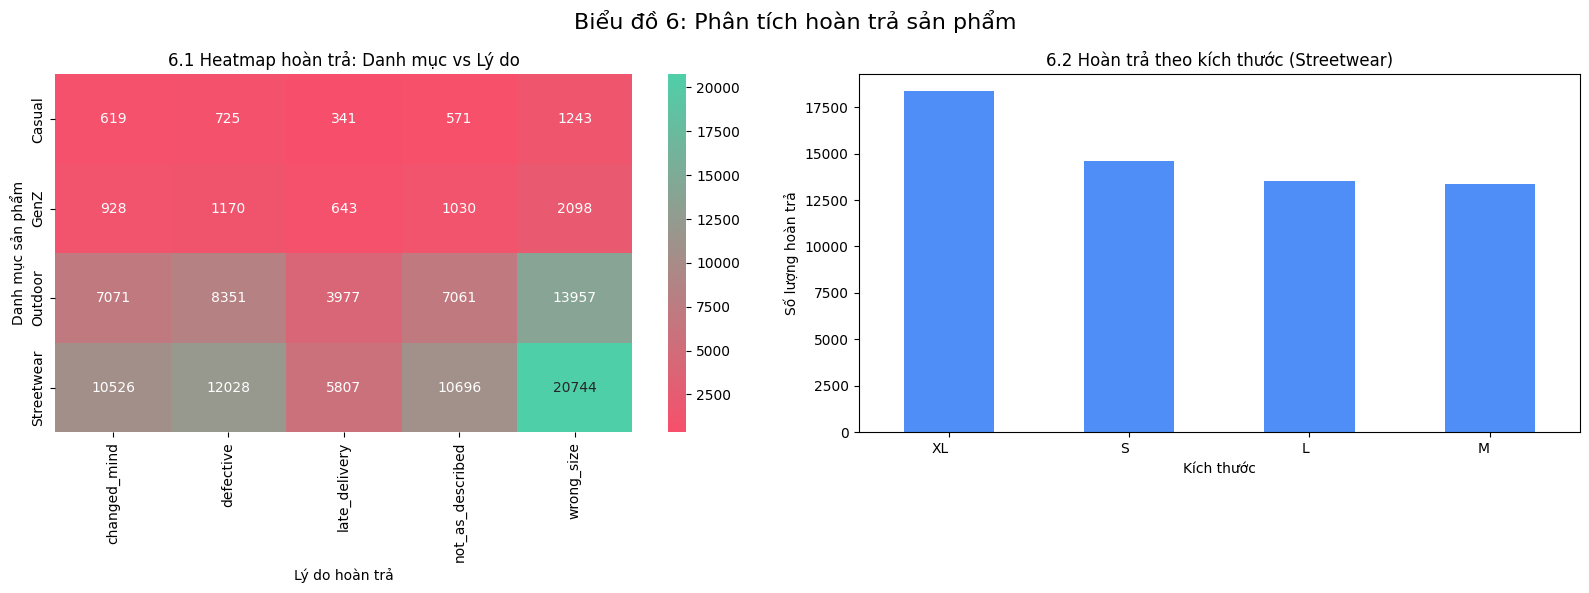

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Biểu đồ 6: Phân tích hoàn trả sản phẩm', fontsize=16)

# Heatmap
sns.heatmap(heatmap_data, annot=True, fmt='.0f', ax=axes[0], cmap=LinearSegmentedColormap.from_list("ret", [PALETTE[0], PALETTE[3]]),)
axes[0].set_title('6.1 Heatmap hoàn trả: Danh mục vs Lý do')
axes[0].set_xlabel('Lý do hoàn trả')
axes[0].set_ylabel('Danh mục sản phẩm')

# Size bar chart
size_plot.plot(kind='bar', ax=axes[1], color=PALETTE[1])
axes[1].set_title(f'6.2 Hoàn trả theo kích thước ({top_category})')
axes[1].set_xlabel('Kích thước')
plt.setp(axes[1].get_xticklabels(), rotation=360, ha='right')
axes[1].set_ylabel('Số lượng hoàn trả')

plt.tight_layout()
plt.show()

## 6. Ai đang bỏ lỡ khuyến mãi?

In [45]:
warnings.filterwarnings("ignore")

USED    = "#3fb950"   # Đã dùng khuyến mãi
MISSED  = "#f78166"   # Bỏ lỡ khuyến mãi
NOPROMO = "#8b949e"   # Không trong thời gian khuyến mãi
YEL     = "#ffa657"
BLU     = "#58a6ff"
PUR     = "#d2a8ff"
TXT     = "#24292f"
GRID    = "#d0d7de"
LIGHT   = "#f6f8fa"

BCOLORS = {
    "Used Promo": USED,
    "Missed Promo": MISSED,
    "No Promo Window": NOPROMO
}

BEHAVIOR_LABEL_MAP = {
    "Used Promo": "Đã dùng khuyến mãi",
    "Missed Promo": "Bỏ lỡ khuyến mãi",
    "No Promo Window": "Không trong thời gian khuyến mãi"
}

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.labelcolor": TXT,
    "xtick.color": "#57606a",
    "ytick.color": "#57606a",
    "text.color": TXT,
    "grid.color": GRID,
    "grid.linewidth": 0.7,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
})

# =========================
# LOAD & TẠO BẢNG MASTER DATA
# =========================

df_orders["order_date"] = pd.to_datetime(df_orders["order_date"])
df_promotion["start_date"] = pd.to_datetime(df_promotion["start_date"])
df_promotion["end_date"] = pd.to_datetime(df_promotion["end_date"])

# Kiểm tra tại ngày đặt hàng có chương trình khuyến mãi đang chạy hay không
order_dates = df_orders[["order_id", "order_date"]].copy()

active_masks = [
    (order_dates["order_date"] >= p["start_date"]) &
    (order_dates["order_date"] <= p["end_date"])
    for _, p in df_promotion.iterrows()
]

order_dates["promo_active"] = np.any(active_masks, axis=0).astype(int)
order_dates["n_active_promos"] = sum(m.astype(int) for m in active_masks)

# Tính giá trị đơn hàng và xác định đơn hàng có dùng khuyến mãi hay không
df_order_items["line_value"] = df_order_items["unit_price"] * df_order_items["quantity"]

df_order_items_agg = (
    df_order_items.groupby("order_id", as_index=False)
    .agg(
        order_value=("line_value", "sum"),
        total_discount=("discount_amount", "sum")
    )
)

promo_orders = df_order_items[df_order_items["promo_id"].notna()]["order_id"].unique()
df_order_items_agg["used_promo"] = df_order_items_agg["order_id"].isin(promo_orders).astype(int)

# Tạo bảng master bằng cách nối orders, order_items, customers và geography
master = (
    df_orders
    .merge(df_order_items_agg, on="order_id", how="left")
    .merge(order_dates[["order_id", "promo_active", "n_active_promos"]], on="order_id", how="left")
    .merge(
        df_customer[["customer_id", "gender", "age_group", "acquisition_channel"]],
        on="customer_id",
        how="left"
    )
    .merge(
        df_geography[["zip", "region"]].drop_duplicates("zip"),
        on="zip",
        how="left"
    )
)

master["year"] = master["order_date"].dt.year

# Phân loại hành vi sử dụng khuyến mãi
def classify_behavior(row):
    if row["promo_active"] == 0:
        return "No Promo Window"
    if row["used_promo"] == 1:
        return "Used Promo"
    return "Missed Promo"

master["promo_behavior"] = master.apply(classify_behavior, axis=1)

# Chỉ xét các đơn hàng nằm trong thời gian có khuyến mãi
in_window = master[master["promo_active"] == 1].copy()
in_window["is_missed"] = (in_window["promo_behavior"] == "Missed Promo").astype(int)

print(master["promo_behavior"].value_counts())

promo_behavior
No Promo Window    347017
Used Promo         248242
Missed Promo        51686
Name: count, dtype: int64


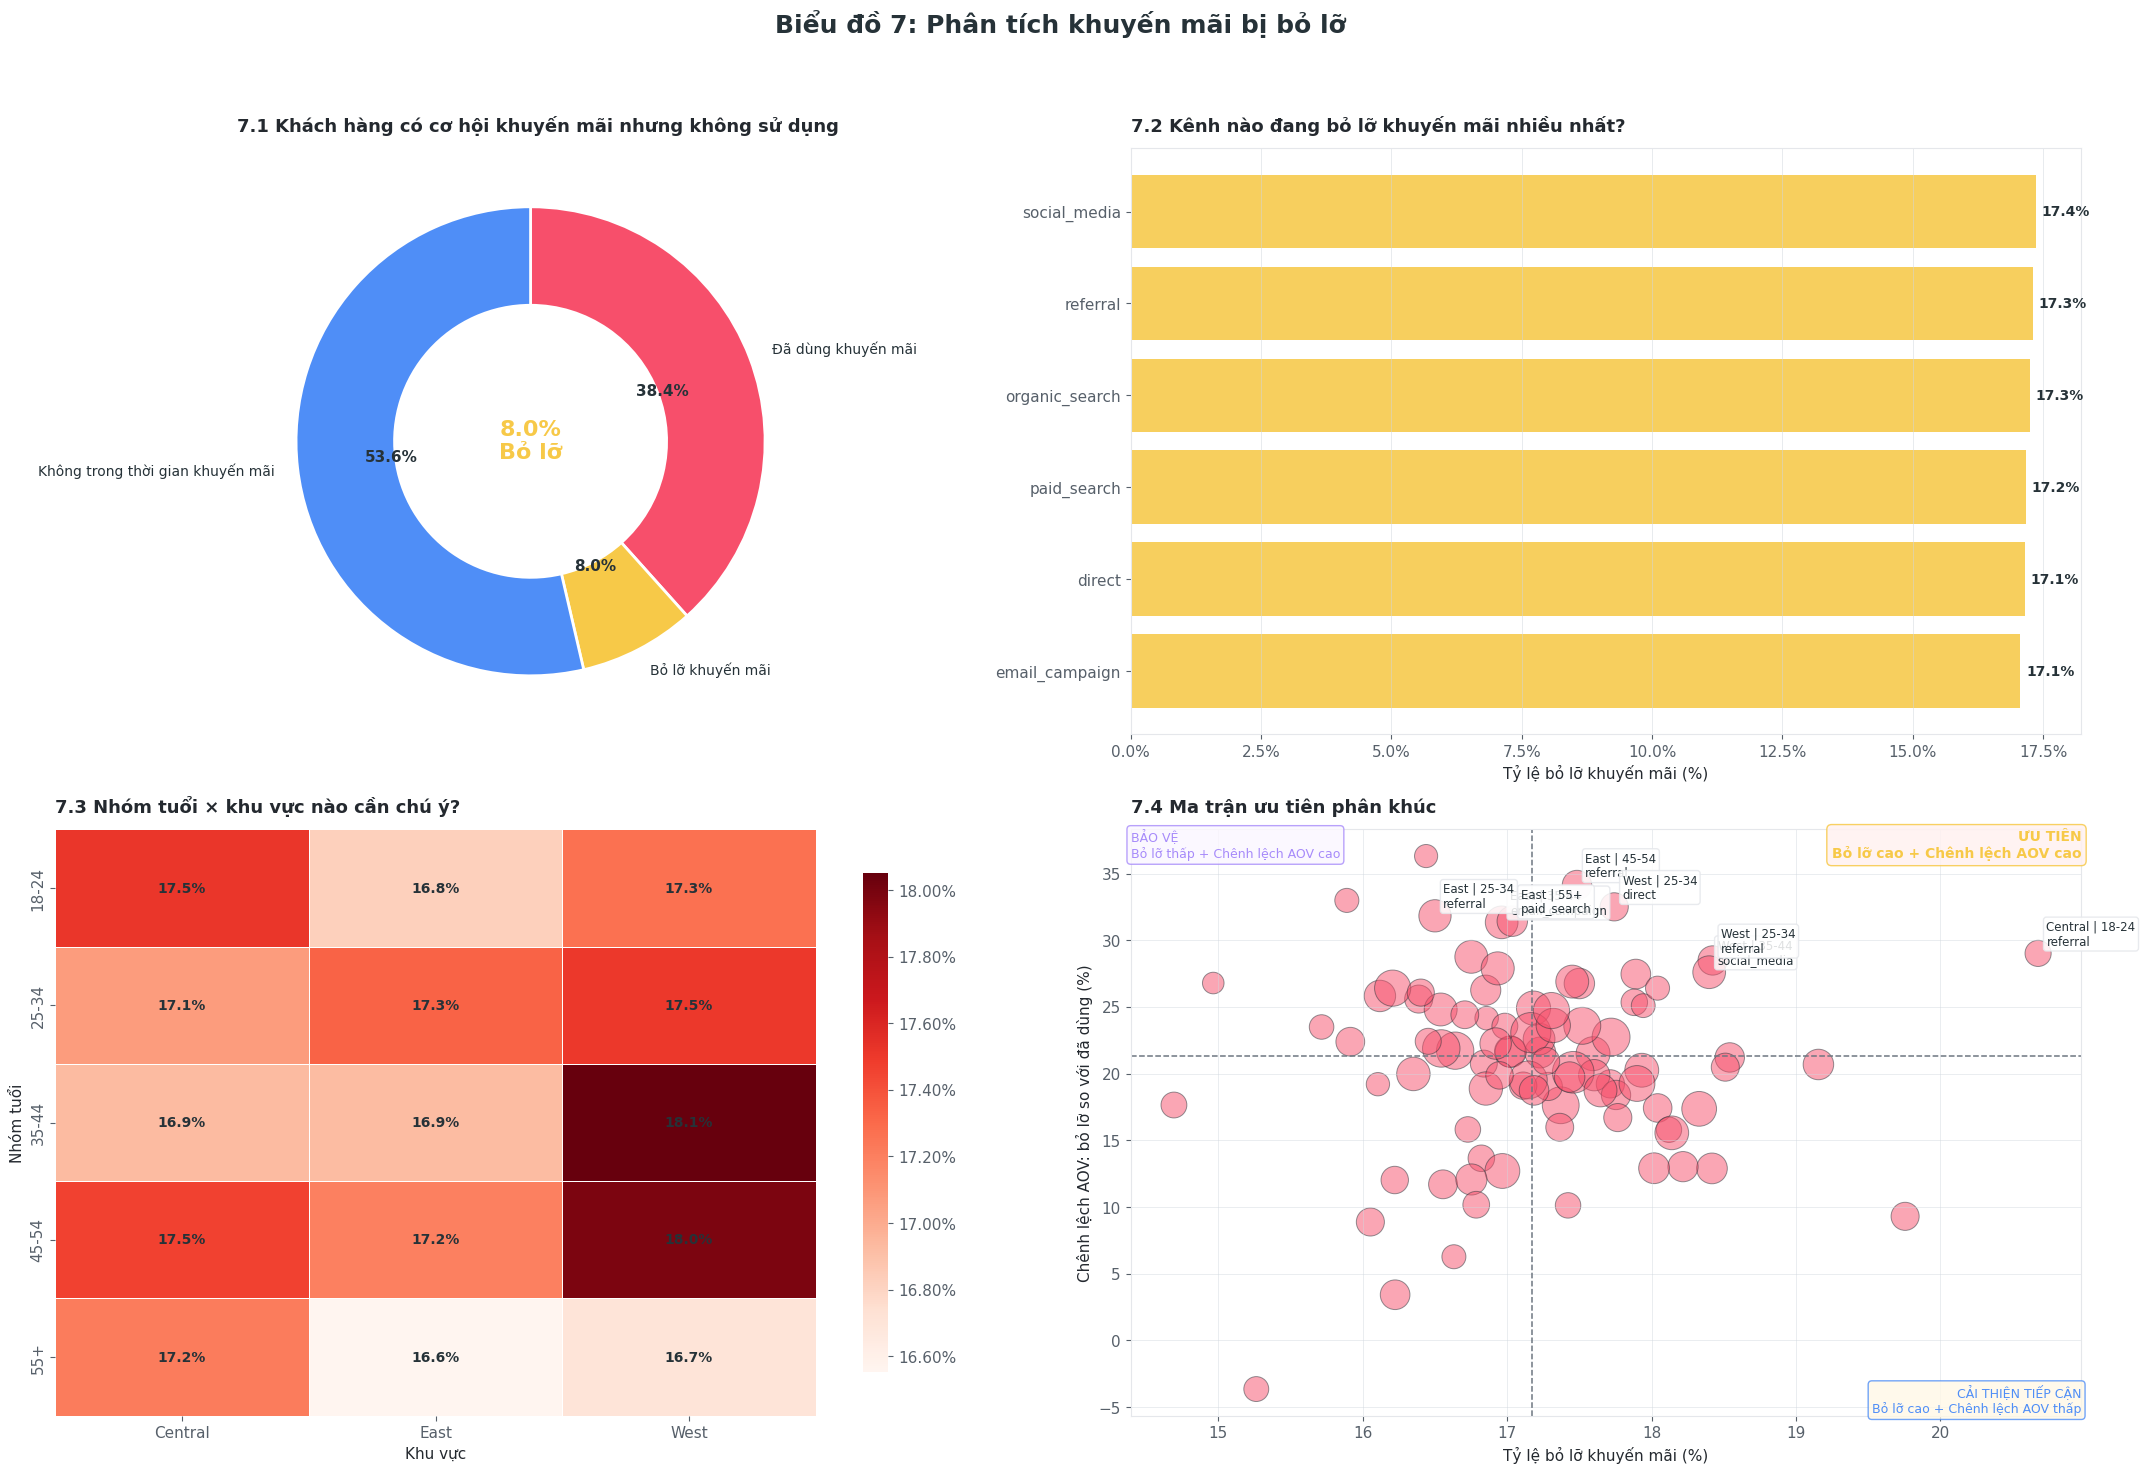


TÓM TẮT BÁO CÁO
Đơn hàng bỏ lỡ khuyến mãi: 51,686 đơn hàng (8.0% tổng số đơn hàng)
Tỷ lệ bỏ lỡ khuyến mãi trong thời gian khuyến mãi: 17.2%

Các kênh có tỷ lệ bỏ lỡ khuyến mãi cao nhất:


,Kênh tiếp cận,Số đơn hàng,Đơn hàng bỏ lỡ,Tỷ lệ bỏ lỡ,AOV
5,social_media,59769,10378,17.4%,"22,766"
4,referral,30038,5198,17.3%,"22,871"
2,organic_search,90296,15580,17.3%,"22,626"
3,paid_search,59664,10244,17.2%,"22,791"
0,direct,24096,4132,17.1%,"22,547"



Các phân khúc ưu tiên hàng đầu:


,Khu vực,Nhóm tuổi,Kênh tiếp cận,Đơn hàng bỏ lỡ,Tỷ lệ bỏ lỡ,Chênh lệch AOV,Điểm cơ hội
52,East,45-54,referral,442.000000,17.5%,34.1%,0.364
43,East,35-44,email_campaign,725.000000,17.0%,31.3%,0.350
40,East,25-34,referral,683.000000,16.5%,31.8%,0.343
66,West,25-34,direct,363.000000,17.7%,32.5%,0.340
57,East,55+,paid_search,522.000000,17.0%,31.4%,0.335
77,West,35-44,social_media,731.000000,18.4%,27.6%,0.335
4,Central,18-24,referral,251.000000,20.7%,29.0%,0.332
70,West,25-34,referral,437.000000,18.4%,28.5%,0.319
15,Central,35-44,paid_search,745.000000,16.8%,28.8%,0.319
69,West,25-34,paid_search,766.000000,16.9%,27.9%,0.314


In [46]:
BLU = PALETTE[0]      
YEL = PALETTE[1]      
MISSED = PALETTE[2]   
GRN = PALETTE[3]      
PUR = PALETTE[4]      
ORG = PALETTE[5]      

TXT = "#263238"
GRID = "#e5e7eb"

BCOLORS = {
    "Used Promo": BLU,
    "Missed Promo": MISSED,
    "No Promo Window": YEL
}

BEHAVIOR_LABEL_MAP = {
    "Used Promo": "Đã dùng khuyến mãi",
    "Missed Promo": "Bỏ lỡ khuyến mãi",
    "No Promo Window": "Không trong thời gian khuyến mãi"
}

# =========================
# Vấn đề → Quy mô → Ai → Làm gì
# =========================

fig, axes = plt.subplots(2, 2, figsize=(22, 15), facecolor="white")

fig.suptitle(
    "Biểu đồ 7: Phân tích khuyến mãi bị bỏ lỡ",
    fontsize=18,
    fontweight="bold",
    color=TXT,
    y=0.98
)

# Biểu đồ 1: Vấn đề
ax = axes[0, 0]

behavior_order = ["Used Promo", "Missed Promo", "No Promo Window"]

sizes = [master["promo_behavior"].value_counts().get(b, 0) for b in behavior_order]
colors = [BCOLORS[b] for b in behavior_order]
labels = [BEHAVIOR_LABEL_MAP[b] for b in behavior_order]

wedges, texts, autotexts = ax.pie(
    sizes,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=colors,
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 10, "color": TXT}
)

for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight("bold")
    at.set_color(TXT)

total_orders = len(master)
missed_orders = (master["promo_behavior"] == "Missed Promo").sum()
missed_total_rate = missed_orders / total_orders if total_orders else 0

ax.text(
    0, 0,
    f"{missed_total_rate:.1%}\nBỏ lỡ",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold",
    color=MISSED
)

ax.set_title(
    "7.1 Khách hàng có cơ hội khuyến mãi nhưng không sử dụng",
    loc="left"
)

# Biểu đồ 2: Quy mô
ax = axes[0, 1]

channel = (
    in_window
    .groupby("acquisition_channel")
    .agg(
        orders=("order_id", "count"),
        missed_orders=("is_missed", "sum"),
        missed_rate=("is_missed", "mean"),
        aov=("order_value", "mean")
    )
    .reset_index()
)

channel = channel[channel["orders"] > 0].sort_values("missed_rate", ascending=True)

bars = ax.barh(
    channel["acquisition_channel"],
    channel["missed_rate"] * 100,
    color=MISSED,
    alpha=0.88
)

ax.bar_label(
    bars,
    labels=[f"{v:.1f}%" for v in channel["missed_rate"] * 100],
    padding=4,
    fontsize=10,
    color=TXT,
    fontweight="bold"
)

ax.set_xlabel("Tỷ lệ bỏ lỡ khuyến mãi (%)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(True, axis="x", alpha=0.5)
ax.set_title(
    "7.2 Kênh nào đang bỏ lỡ khuyến mãi nhiều nhất?",
    loc="left"
)

# Biểu đồ 3: Ai
ax = axes[1, 0]

pivot = (
    in_window
    .groupby(["age_group", "region"])["is_missed"]
    .mean()
    .unstack()
)

annot = pivot.applymap(lambda x: "" if pd.isna(x) else f"{x:.1%}")

sns.heatmap(
    pivot,
    ax=ax,
    cmap="Reds",
    annot=annot,
    fmt="",
    linewidths=0.7,
    linecolor="white",
    cbar_kws={"shrink": 0.85, "format": mticker.PercentFormatter(xmax=1)},
    annot_kws={"size": 10, "weight": "bold", "color": TXT}
)

ax.set_xlabel("Khu vực")
ax.set_ylabel("Nhóm tuổi")
ax.set_title(
    "7.3 Nhóm tuổi × khu vực nào cần chú ý?",
    loc="left"
)

# Biểu đồ 4: Làm gì?
ax = axes[1, 1]

segment = (
    in_window
    .groupby(["region", "age_group", "acquisition_channel"])
    .apply(lambda x: pd.Series({
        "orders": len(x),
        "missed_orders": (x["promo_behavior"] == "Missed Promo").sum(),
        "missed_rate": (x["promo_behavior"] == "Missed Promo").mean(),
        "aov_missed": x.loc[x["promo_behavior"] == "Missed Promo", "order_value"].mean(),
        "aov_used": x.loc[x["promo_behavior"] == "Used Promo", "order_value"].mean(),
    }))
    .reset_index()
)

segment = segment[
    (segment["orders"] >= 100) &
    (segment["missed_orders"] > 0) &
    (segment["aov_missed"].notna()) &
    (segment["aov_used"].notna())
].copy()

segment["aov_gap_pct"] = (
    (segment["aov_missed"] - segment["aov_used"]) /
    segment["aov_used"]
)

segment["opportunity_score"] = (
    segment["missed_rate"] *
    segment["aov_gap_pct"].clip(lower=0) *
    np.log1p(segment["missed_orders"])
)

if segment.empty:
    ax.text(
        0.5, 0.5,
        "Không đủ dữ liệu để vẽ ma trận ưu tiên",
        ha="center",
        va="center",
        fontsize=13,
        color=TXT,
        transform=ax.transAxes
    )
    ax.set_axis_off()
else:
    x_med = segment["missed_rate"].median()
    y_med = segment["aov_gap_pct"].median()

    sizes = 70 + 18 * np.sqrt(segment["missed_orders"])

    ax.scatter(
        segment["missed_rate"] * 100,
        segment["aov_gap_pct"] * 100,
        s=sizes,
        color=BLU,
        alpha=0.50,
        edgecolors=TXT,
        linewidth=0.7
    )

    ax.axvline(x_med * 100, color="#6e7781", linestyle="--", linewidth=1.1)
    ax.axhline(y_med * 100, color="#6e7781", linestyle="--", linewidth=1.1)

    top_labels = (
        segment
        .sort_values("opportunity_score", ascending=False)
        .head(8)
    )

    for _, row in top_labels.iterrows():
        label = f"{row['region']} | {row['age_group']}\n{row['acquisition_channel']}"

        ax.annotate(
            label,
            (row["missed_rate"] * 100, row["aov_gap_pct"] * 100),
            textcoords="offset points",
            xytext=(6, 6),
            fontsize=8.5,
            color=TXT,
            bbox=dict(
                boxstyle="round,pad=0.25",
                fc="white",
                ec=GRID,
                alpha=0.85
            )
        )

    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()

    ax.text(
        x_max, y_max,
        "ƯU TIÊN\nBỏ lỡ cao + Chênh lệch AOV cao",
        ha="right",
        va="top",
        fontsize=10,
        fontweight="bold",
        color=MISSED,
        bbox=dict(boxstyle="round,pad=0.35", fc="#fff1f0", ec=MISSED, alpha=0.85)
    )

    ax.text(
        x_min, y_max,
        "BẢO VỆ\nBỏ lỡ thấp + Chênh lệch AOV cao",
        ha="left",
        va="top",
        fontsize=9,
        color=PUR,
        bbox=dict(boxstyle="round,pad=0.30", fc="#fbf7ff", ec=PUR, alpha=0.80)
    )

    ax.text(
        x_max, y_min,
        "CẢI THIỆN TIẾP CẬN\nBỏ lỡ cao + Chênh lệch AOV thấp",
        ha="right",
        va="bottom",
        fontsize=9,
        color=YEL,
        bbox=dict(boxstyle="round,pad=0.30", fc="#fff8e6", ec=YEL, alpha=0.80)
    )

    ax.set_xlabel("Tỷ lệ bỏ lỡ khuyến mãi (%)")
    ax.set_ylabel("Chênh lệch AOV: bỏ lỡ so với đã dùng (%)")
    ax.grid(True, alpha=0.45)

ax.set_title(
    "7.4 Ma trận ưu tiên phân khúc",
    loc="left"
)

for ax_i in axes.flat:
    ax_i.set_facecolor("white")
    for spine in ax_i.spines.values():
        spine.set_color(GRID)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# =========================
# TÓM TẮT BỔ SUNG CHO BÁO CÁO
# =========================

missed_rate_in_window = in_window["is_missed"].mean()

print("\nTÓM TẮT BÁO CÁO")
print("=" * 70)
print(f"Đơn hàng bỏ lỡ khuyến mãi: {missed_orders:,} đơn hàng ({missed_total_rate:.1%} tổng số đơn hàng)")
print(f"Tỷ lệ bỏ lỡ khuyến mãi trong thời gian khuyến mãi: {missed_rate_in_window:.1%}")

print("\nCác kênh có tỷ lệ bỏ lỡ khuyến mãi cao nhất:")

channel_report = (
    channel
    .sort_values("missed_rate", ascending=False)
    [["acquisition_channel", "orders", "missed_orders", "missed_rate", "aov"]]
    .head(5)
    .copy()
)

channel_report = channel_report.rename(columns={
    "acquisition_channel": "Kênh tiếp cận",
    "orders": "Số đơn hàng",
    "missed_orders": "Đơn hàng bỏ lỡ",
    "missed_rate": "Tỷ lệ bỏ lỡ",
    "aov": "AOV"
})

display(
    channel_report.style.format({
        "Tỷ lệ bỏ lỡ": "{:.1%}",
        "AOV": "{:,.0f}"
    })
)

print("\nCác phân khúc ưu tiên hàng đầu:")

if segment.empty:
    print("Không có phân khúc đủ điều kiện để hiển thị.")
else:
    segment_report = (
        segment
        .sort_values("opportunity_score", ascending=False)
        [["region", "age_group", "acquisition_channel", "missed_orders", "missed_rate", "aov_gap_pct", "opportunity_score"]]
        .head(10)
        .copy()
    )

    segment_report = segment_report.rename(columns={
        "region": "Khu vực",
        "age_group": "Nhóm tuổi",
        "acquisition_channel": "Kênh tiếp cận",
        "missed_orders": "Đơn hàng bỏ lỡ",
        "missed_rate": "Tỷ lệ bỏ lỡ",
        "aov_gap_pct": "Chênh lệch AOV",
        "opportunity_score": "Điểm cơ hội"
    })

    display(
        segment_report.style.format({
            "Tỷ lệ bỏ lỡ": "{:.1%}",
            "Chênh lệch AOV": "{:.1%}",
            "Điểm cơ hội": "{:.3f}"
        })
    )